# Tugas 05 — Transfer Learning untuk Klasifikasi Citra dengan Data Terbatas

**Nama:** Jonathan Kuniardi  **NIM:** 2802461832
**Dataset:** Oxford-IIIT Pet, subset 10 kelas (5 ras kucing, 5 ras anjing)
**Arsitektur utama:** ResNet-18 (`ResNet18_Weights.IMAGENET1K_V1`)  **Runtime:** Google Colab, GPU T4

| Kode | Kondisi | Ringkas |
|---|---|---|
| B1 | Baseline from scratch | ResNet-18 `weights=None`, semua layer dilatih |
| B2 | Feature extraction | backbone dibekukan, hanya `fc` dilatih |
| B3 | Progressive fine-tuning | `layer4` + `fc` dilatih, differential LR (1e-4 / 1e-3) |
| B4 | Uji kontrol augmentasi | B3 dijalankan ulang **tanpa** augmentasi, dibandingkan dengan B3 (dengan augmentasi) |
| B5 | Arsitektur pembanding | konfigurasi terbaik (dipilih dari data validasi) pada EfficientNet-B0 dan MobileNetV3-Small |

Semua angka di laporan diambil dari berkas di folder `results/` yang dihasilkan notebook ini.

## 0. Setup lingkungan

In [1]:
import os, json, time, random, copy
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
from PIL import Image

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import torchvision
from torchvision import models, transforms
from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score, accuracy_score, confusion_matrix, classification_report

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("torch       :", torch.__version__)
print("torchvision :", torchvision.__version__)
print("device      :", device, "|", torch.cuda.get_device_name(0) if device.type == "cuda" else "CPU")

torch       : 2.11.0+cu130
torchvision : 0.26.0+cu130
device      : cuda | Tesla T4


## 1. Konfigurasi eksperimen dan seed

In [2]:
SEED          = 42
BATCH_SIZE    = 32
MAX_EPOCHS    = 30        # batas atas; early stopping biasanya berhenti lebih dulu
PATIENCE      = 5         # early stopping pada validation loss
WEIGHT_DECAY  = 1e-2      # AdamW
LR_SCRATCH    = 1e-3      # B1: satu LR untuk seluruh jaringan
LR_HEAD       = 1e-3      # classifier head (B2, B3, B5)
LR_BACKBONE   = 1e-4      # blok terakhir backbone yang di-unfreeze (B3, B5)
NUM_WORKERS   = 2

# 5 ras kucing + 5 ras anjing (nama sesuai OxfordIIITPet.classes)
SELECTED_CLASSES = [
    "Abyssinian", "Bengal", "British Shorthair", "Russian Blue", "Siamese",   # kucing
    "Basset Hound", "Beagle", "Pug", "Samoyed", "Shiba Inu",                  # anjing
]
NUM_CLASSES = len(SELECTED_CLASSES)

DATA_ROOT   = Path("data")
RESULTS_DIR = Path("results")
CKPT_DIR    = Path("checkpoints")    # bobot model (besar, tidak ikut ZIP/GitHub)
RESULTS_DIR.mkdir(exist_ok=True); CKPT_DIR.mkdir(exist_ok=True)

In [3]:
def set_seed(seed: int = SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

def seed_worker(worker_id):
    # setiap worker DataLoader mendapat seed turunan yang tetap
    worker_seed = torch.initial_seed() % 2**32
    np.random.seed(worker_seed)
    random.seed(worker_seed)

set_seed(SEED)

## 2. Dataset dan pembagian data

Split bawaan `trainval` dan `test` digabung dulu (±200 citra per kelas), lalu dibagi ulang secara
stratified 70/15/15 sesuai ketentuan tugas. Pembagian dilakukan **sekali**, berdasarkan path berkas,
sebelum transformasi apa pun, sehingga citra uji tidak pernah masuk ke data latih.

In [4]:
pet_trainval = torchvision.datasets.OxfordIIITPet(root=DATA_ROOT, split="trainval", target_types="category", download=True)
pet_test     = torchvision.datasets.OxfordIIITPet(root=DATA_ROOT, split="test",     target_types="category", download=True)

missing = [c for c in SELECTED_CLASSES if c not in pet_trainval.classes]
assert not missing, f"Nama kelas tidak ditemukan: {missing}"

orig_to_new = {pet_trainval.class_to_idx[c]: i for i, c in enumerate(SELECTED_CLASSES)}

# (_images, _labels) adalah atribut internal torchvision: daftar path citra dan label asli 0..36
all_paths, all_labels = [], []
for ds in (pet_trainval, pet_test):
    for path, lab in zip(ds._images, ds._labels):
        if lab in orig_to_new:
            all_paths.append(str(path))
            all_labels.append(orig_to_new[lab])
all_paths, all_labels = np.array(all_paths), np.array(all_labels)
print("Total citra 10 kelas:", len(all_paths))

100%|██████████| 792M/792M [00:30<00:00, 26.1MB/s]
100%|██████████| 19.2M/19.2M [00:01<00:00, 12.7MB/s]


Total citra 10 kelas: 1997


In [5]:
idx = np.arange(len(all_paths))
train_idx, temp_idx = train_test_split(idx, test_size=0.30, stratify=all_labels, random_state=SEED)
val_idx, test_idx   = train_test_split(temp_idx, test_size=0.50, stratify=all_labels[temp_idx], random_state=SEED)

assert set(train_idx).isdisjoint(val_idx) and set(train_idx).isdisjoint(test_idx) and set(val_idx).isdisjoint(test_idx)

split_df = pd.DataFrame({
    "path": all_paths,
    "label": all_labels,
    "class": [SELECTED_CLASSES[l] for l in all_labels],
    "split": "",
})
split_df.loc[train_idx, "split"] = "train"
split_df.loc[val_idx,   "split"] = "val"
split_df.loc[test_idx,  "split"] = "test"
split_df["path"] = split_df["path"].map(lambda p: Path(p).name)   # simpan nama berkas saja
split_df.to_csv(RESULTS_DIR / "data_split.csv", index=False)

counts = split_df.pivot_table(index="class", columns="split", values="label", aggfunc="count")[["train", "val", "test"]]
counts.loc["TOTAL"] = counts.sum()
counts

split,train,val,test
class,,,
Abyssinian,138,30,30
Basset Hound,140,30,30
Beagle,140,30,30
Bengal,140,30,30
British Shorthair,140,30,30
Pug,140,30,30
Russian Blue,140,30,30
Samoyed,140,30,30
Shiba Inu,140,30,30


In [6]:
class PetSubset(Dataset):
    # Subset Oxford-IIIT Pet: setiap subset punya transform sendiri.
    def __init__(self, paths, labels, transform):
        self.paths, self.labels, self.transform = list(paths), list(labels), transform
    def __len__(self):
        return len(self.paths)
    def __getitem__(self, i):
        img = Image.open(self.paths[i]).convert("RGB")
        return self.transform(img), self.labels[i]

train_paths, train_labels = all_paths[train_idx], all_labels[train_idx]
val_paths,   val_labels   = all_paths[val_idx],   all_labels[val_idx]
test_paths,  test_labels  = all_paths[test_idx],  all_labels[test_idx]
print(f"train={len(train_paths)}  val={len(val_paths)}  test={len(test_paths)}")

train=1397  val=300  test=300


## 3. Pipeline transformasi

In [7]:
weights_r18 = models.ResNet18_Weights.IMAGENET1K_V1
eval_tf = weights_r18.transforms()          # Resize 256 -> CenterCrop 224 -> Normalize ImageNet
MEAN, STD = eval_tf.mean, eval_tf.std

# Augmentasi: HANYA dipakai untuk data latih
train_aug_tf = transforms.Compose([
    transforms.Resize(256),
    transforms.RandomResizedCrop(224, scale=(0.8, 1.0)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize(mean=MEAN, std=STD),
])
# Tanpa augmentasi (kontrol B4): hanya Resize/Crop + Normalize, identik dengan eval
train_noaug_tf = eval_tf

print(eval_tf)

ImageClassification(
    crop_size=[224]
    resize_size=[256]
    mean=[0.485, 0.456, 0.406]
    std=[0.229, 0.224, 0.225]
    interpolation=InterpolationMode.BILINEAR
)


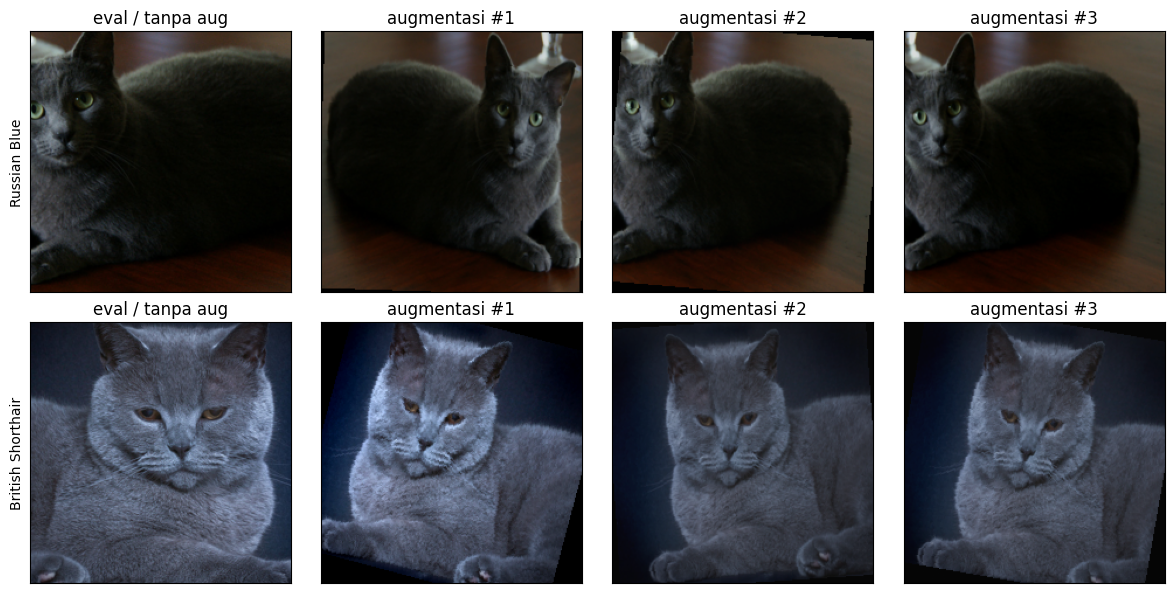

In [8]:
def denormalize(t):
    m = torch.tensor(MEAN).view(3, 1, 1); s = torch.tensor(STD).view(3, 1, 1)
    return (t * s + m).clamp(0, 1).permute(1, 2, 0).numpy()

# Contoh visual: citra yang sama dengan eval transform vs 3 sampel augmentasi
set_seed(SEED)
fig, axes = plt.subplots(2, 4, figsize=(12, 6))
for r, i in enumerate([0, 7]):
    img = Image.open(train_paths[i]).convert("RGB")
    axes[r, 0].imshow(denormalize(eval_tf(img))); axes[r, 0].set_title("eval / tanpa aug")
    for c in range(1, 4):
        axes[r, c].imshow(denormalize(train_aug_tf(img))); axes[r, c].set_title(f"augmentasi #{c}")
    axes[r, 0].set_ylabel(SELECTED_CLASSES[train_labels[i]])
for ax in axes.flat: ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout(); plt.savefig(RESULTS_DIR / "augmentation_examples.png", dpi=120); plt.show()

## 4. Pembangun model dan strategi pembekuan

`strategy`:
- `scratch` — bobot acak, semua parameter dilatih (B1)
- `feature_extraction` — bobot ImageNet, backbone dibekukan, hanya head dilatih (B2)
- `finetune` — bobot ImageNet, blok terakhir backbone + head dilatih dengan differential LR (B3)

Untuk B5, padanan "blok terakhir": EfficientNet-B0 `features[7:]` (stage terakhir + conv 1×1 akhir),
MobileNetV3-Small `features[9:]` (tiga blok inverted residual terakhir + conv akhir).

In [9]:
ARCHS = {
    "resnet18":           (models.resnet18,           models.ResNet18_Weights.IMAGENET1K_V1),
    "efficientnet_b0":    (models.efficientnet_b0,    models.EfficientNet_B0_Weights.IMAGENET1K_V1),
    "mobilenet_v3_small": (models.mobilenet_v3_small, models.MobileNet_V3_Small_Weights.IMAGENET1K_V1),
}

def build_model(arch, strategy, num_classes=NUM_CLASSES):
    builder, w = ARCHS[arch]
    model = builder(weights=None if strategy == "scratch" else w)

    # ganti classifier head -> num_classes, tentukan "blok terakhir" backbone
    if arch == "resnet18":
        model.fc = nn.Linear(model.fc.in_features, num_classes)
        head, last_block = model.fc, model.layer4
        head_name, block_name = "fc", "layer4"
    elif arch == "efficientnet_b0":
        model.classifier[1] = nn.Linear(model.classifier[1].in_features, num_classes)
        head, last_block = model.classifier, model.features[7:]
        head_name, block_name = "classifier", "features[7:]"
    elif arch == "mobilenet_v3_small":
        model.classifier[3] = nn.Linear(model.classifier[3].in_features, num_classes)
        head, last_block = model.classifier, model.features[9:]
        head_name, block_name = "classifier", "features[9:]"

    if strategy == "scratch":
        groups = [{"name": "all", "params": list(model.parameters()), "lr": LR_SCRATCH}]
    else:
        for p in model.parameters():
            p.requires_grad = False
        for p in head.parameters():
            p.requires_grad = True
        groups = [{"name": head_name, "params": list(head.parameters()), "lr": LR_HEAD}]
        if strategy == "finetune":
            for p in last_block.parameters():
                p.requires_grad = True
            groups.insert(0, {"name": block_name, "params": list(last_block.parameters()), "lr": LR_BACKBONE})
    return model, groups

def count_params(model):
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    total = sum(p.numel() for p in model.parameters())
    return trainable, total

def set_frozen_bn_to_eval(model):
    # BatchNorm yang parameternya beku juga dibekukan statistik running-nya
    for m in model.modules():
        if isinstance(m, nn.modules.batchnorm._BatchNorm):
            if not any(p.requires_grad for p in m.parameters()):
                m.eval()

# Verifikasi jumlah parameter sebelum optimizer dibentuk
for strat in ["scratch", "feature_extraction", "finetune"]:
    m, g = build_model("resnet18", strat)
    tr, tot = count_params(m)
    print(f"{strat:20s} trainable = {tr:>10,} / {tot:,}")
del m

scratch              trainable = 11,181,642 / 11,181,642
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 142MB/s]


feature_extraction   trainable =      5,130 / 11,181,642
finetune             trainable =  8,398,858 / 11,181,642


## 5. Training loop, early stopping, dan pencatatan metrik

In [10]:
EPOCH_LOG, SUMMARY = [], []

def make_loader(paths, labels, tf, shuffle):
    g = torch.Generator(); g.manual_seed(SEED)
    return DataLoader(PetSubset(paths, labels, tf), batch_size=BATCH_SIZE, shuffle=shuffle,
                      num_workers=NUM_WORKERS, worker_init_fn=seed_worker, generator=g,
                      pin_memory=(device.type == "cuda"))

def run_epoch(model, loader, criterion, optimizer=None):
    training = optimizer is not None
    model.train(training)
    if training:
        set_frozen_bn_to_eval(model)
    total_loss, correct, n = 0.0, 0, 0
    with torch.set_grad_enabled(training):
        for x, y in loader:
            x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
            logits = model(x)
            loss = criterion(logits, y)
            if training:
                optimizer.zero_grad(set_to_none=True)
                loss.backward()
                optimizer.step()
            total_loss += loss.item() * x.size(0)
            correct += (logits.argmax(1) == y).sum().item()
            n += x.size(0)
    return total_loss / n, correct / n

@torch.no_grad()
def predict(model, loader):
    model.eval()
    probs, ys = [], []
    for x, y in loader:
        probs.append(F.softmax(model(x.to(device)), dim=1).cpu())
        ys.append(y)
    probs = torch.cat(probs).numpy(); ys = torch.cat(ys).numpy()
    return ys, probs.argmax(1), probs

def save_logs():
    pd.DataFrame(EPOCH_LOG).to_csv(RESULTS_DIR / "epoch_log.csv", index=False)
    pd.DataFrame(SUMMARY).to_csv(RESULTS_DIR / "summary.csv", index=False)
    with open(RESULTS_DIR / "summary.json", "w") as f:
        json.dump(SUMMARY, f, indent=2)

In [11]:
def run_experiment(exp_id, condition, arch, strategy, augment):
    set_seed(SEED)
    train_loader      = make_loader(train_paths, train_labels, train_aug_tf if augment else train_noaug_tf, shuffle=True)
    train_eval_loader = make_loader(train_paths, train_labels, eval_tf, shuffle=False)   # untuk mengukur gap
    val_loader        = make_loader(val_paths, val_labels, eval_tf, shuffle=False)
    test_loader       = make_loader(test_paths, test_labels, eval_tf, shuffle=False)

    model, groups = build_model(arch, strategy)
    model.to(device)
    trainable, total = count_params(model)
    optimizer = torch.optim.AdamW([{"params": g["params"], "lr": g["lr"]} for g in groups], weight_decay=WEIGHT_DECAY)
    criterion = nn.CrossEntropyLoss()
    lr_str = "; ".join(f"{g['name']}={g['lr']:g}" for g in groups)
    print(f"[{exp_id}] {condition} | {arch} | aug={augment} | trainable={trainable:,}/{total:,} | lr: {lr_str}")

    best_val_loss, best_state, best_epoch, bad_epochs = float("inf"), None, 0, 0
    t_start = time.time()
    for epoch in range(1, MAX_EPOCHS + 1):
        t0 = time.time()
        tr_loss, tr_acc = run_epoch(model, train_loader, criterion, optimizer)
        va_loss, va_acc = run_epoch(model, val_loader, criterion)
        dt = time.time() - t0
        EPOCH_LOG.append(dict(exp_id=exp_id, epoch=epoch, train_loss=tr_loss, train_acc=tr_acc,
                              val_loss=va_loss, val_acc=va_acc, epoch_time_s=dt))
        improved = va_loss < best_val_loss - 1e-4
        if improved:
            best_val_loss, best_epoch, bad_epochs = va_loss, epoch, 0
            best_state = copy.deepcopy(model.state_dict())
        else:
            bad_epochs += 1
        print(f"  ep {epoch:02d} | train {tr_loss:.4f}/{tr_acc:.3f} | val {va_loss:.4f}/{va_acc:.3f} | {dt:5.1f}s {'*' if improved else ''}")
        if bad_epochs >= PATIENCE:
            print(f"  early stopping: val loss tidak membaik selama {PATIENCE} epoch")
            break
    train_time = time.time() - t_start

    # evaluasi memakai bobot terbaik (epoch dengan val loss terendah)
    model.load_state_dict(best_state)
    torch.save(best_state, CKPT_DIR / f"{exp_id}.pt")
    _, tr_pred, _          = predict(model, train_eval_loader)
    va_true, va_pred, _    = predict(model, val_loader)
    te_true, te_pred, te_p = predict(model, test_loader)

    row = dict(
        exp_id=exp_id, condition=condition, arch=arch, strategy=strategy, augmentation=augment,
        trainable_params=trainable, total_params=total, lr_groups=lr_str,
        best_epoch=best_epoch, epochs_run=epoch, train_time_s=round(train_time, 1),
        best_val_loss=best_val_loss,
        train_acc_clean=accuracy_score(train_labels, tr_pred),
        val_acc=accuracy_score(va_true, va_pred),
        val_macro_f1=f1_score(va_true, va_pred, average="macro"),
        test_acc=accuracy_score(te_true, te_pred),
        test_macro_f1=f1_score(te_true, te_pred, average="macro"),
        seed=SEED,
    )
    row["gen_gap"] = row["train_acc_clean"] - row["val_acc"]
    SUMMARY.append(row)

    pred_df = pd.DataFrame(te_p, columns=[f"p_{c}" for c in SELECTED_CLASSES])
    pred_df.insert(0, "file", [Path(p).name for p in test_paths])
    pred_df.insert(1, "true", [SELECTED_CLASSES[i] for i in te_true])
    pred_df.insert(2, "pred", [SELECTED_CLASSES[i] for i in te_pred])
    pred_df.insert(3, "confidence", te_p.max(1))
    pred_df.to_csv(RESULTS_DIR / f"test_predictions_{exp_id}.csv", index=False)
    save_logs()

    print(f"  -> best epoch {best_epoch} | val acc {row['val_acc']:.4f} | test acc {row['test_acc']:.4f} "
          f"| test macro F1 {row['test_macro_f1']:.4f} | {train_time/60:.1f} menit")
    return model

## 6. Eksperimen
### B1 — Baseline from scratch

In [12]:
model_b1 = run_experiment("B1", "Baseline from scratch", "resnet18", "scratch", augment=True)

[B1] Baseline from scratch | resnet18 | aug=True | trainable=11,181,642/11,181,642 | lr: all=0.001
  ep 01 | train 2.3002/0.193 | val 4.8676/0.137 |  16.7s *
  ep 02 | train 2.0843/0.260 | val 2.6893/0.237 |  14.2s *
  ep 03 | train 1.9333/0.322 | val 1.8712/0.360 |  16.0s *
  ep 04 | train 1.8392/0.354 | val 2.0952/0.280 |  14.2s 
  ep 05 | train 1.6467/0.409 | val 2.3882/0.257 |  14.7s 
  ep 06 | train 1.6436/0.410 | val 1.8869/0.373 |  15.1s 
  ep 07 | train 1.5773/0.445 | val 1.5641/0.373 |  14.5s *
  ep 08 | train 1.4887/0.469 | val 1.7930/0.403 |  14.1s 
  ep 09 | train 1.3737/0.510 | val 1.7911/0.450 |  14.4s 
  ep 10 | train 1.3097/0.530 | val 1.5174/0.467 |  14.2s *
  ep 11 | train 1.2506/0.560 | val 1.6973/0.433 |  14.2s 
  ep 12 | train 1.2041/0.561 | val 1.5368/0.467 |  14.3s 
  ep 13 | train 1.1458/0.597 | val 1.8139/0.403 |  14.2s 
  ep 14 | train 1.1135/0.613 | val 1.7721/0.430 |  14.3s 
  ep 15 | train 1.0750/0.613 | val 1.5202/0.473 |  14.5s 
  early stopping: val loss

### B2 — Feature extraction

In [13]:
model_b2 = run_experiment("B2", "Feature extraction", "resnet18", "feature_extraction", augment=True)

[B2] Feature extraction | resnet18 | aug=True | trainable=5,130/11,181,642 | lr: fc=0.001
  ep 01 | train 1.2148/0.665 | val 0.5987/0.873 |  13.4s *
  ep 02 | train 0.4862/0.888 | val 0.3676/0.927 |  15.7s *
  ep 03 | train 0.3454/0.922 | val 0.2994/0.920 |  13.4s *
  ep 04 | train 0.2764/0.940 | val 0.2613/0.930 |  13.5s *
  ep 05 | train 0.2365/0.944 | val 0.2345/0.927 |  13.5s *
  ep 06 | train 0.2159/0.945 | val 0.2184/0.927 |  13.5s *
  ep 07 | train 0.1883/0.952 | val 0.2122/0.940 |  13.7s *
  ep 08 | train 0.1878/0.951 | val 0.2027/0.943 |  13.6s *
  ep 09 | train 0.1684/0.956 | val 0.2015/0.930 |  13.5s *
  ep 10 | train 0.1499/0.960 | val 0.1978/0.937 |  13.4s *
  ep 11 | train 0.1531/0.961 | val 0.2078/0.933 |  13.7s 
  ep 12 | train 0.1395/0.964 | val 0.1920/0.937 |  13.7s *
  ep 13 | train 0.1345/0.965 | val 0.1842/0.933 |  13.6s *
  ep 14 | train 0.1348/0.963 | val 0.1822/0.930 |  13.4s *
  ep 15 | train 0.1311/0.961 | val 0.1844/0.943 |  13.7s 
  ep 16 | train 0.1171/0.97

### B3 — Progressive fine-tuning (layer4 + fc, differential LR)

In [14]:
model_b3 = run_experiment("B3", "Progressive fine-tuning", "resnet18", "finetune", augment=True)

[B3] Progressive fine-tuning | resnet18 | aug=True | trainable=8,398,858/11,181,642 | lr: layer4=0.0001; fc=0.001
  ep 01 | train 0.7008/0.791 | val 0.2296/0.917 |  13.4s *
  ep 02 | train 0.1572/0.966 | val 0.1827/0.923 |  14.9s *
  ep 03 | train 0.1023/0.971 | val 0.1888/0.923 |  13.3s 
  ep 04 | train 0.0646/0.982 | val 0.2060/0.940 |  13.6s 
  ep 05 | train 0.0395/0.991 | val 0.1633/0.953 |  13.7s *
  ep 06 | train 0.0414/0.991 | val 0.2101/0.927 |  13.4s 
  ep 07 | train 0.0294/0.994 | val 0.1921/0.933 |  13.6s 
  ep 08 | train 0.0254/0.996 | val 0.1874/0.937 |  13.6s 
  ep 09 | train 0.0212/0.994 | val 0.1950/0.933 |  13.6s 
  ep 10 | train 0.0179/0.995 | val 0.1651/0.947 |  13.4s 
  early stopping: val loss tidak membaik selama 5 epoch
  -> best epoch 5 | val acc 0.9533 | test acc 0.9400 | test macro F1 0.9402 | 2.3 menit


### B4 — Uji kontrol augmentasi

Kondisi B3 dijalankan ulang **tanpa** augmentasi (`B4_noaug`). Skenario *dengan* augmentasi adalah run B3
di atas — konfigurasi, seed, dan split-nya identik, sehingga satu-satunya variabel yang berubah adalah augmentasi.

In [15]:
model_b4 = run_experiment("B4_noaug", "B3 tanpa augmentasi", "resnet18", "finetune", augment=False)

[B4_noaug] B3 tanpa augmentasi | resnet18 | aug=False | trainable=8,398,858/11,181,642 | lr: layer4=0.0001; fc=0.001
  ep 01 | train 0.6247/0.820 | val 0.1981/0.923 |   8.8s *
  ep 02 | train 0.0773/0.988 | val 0.1676/0.933 |  10.0s *
  ep 03 | train 0.0258/0.998 | val 0.1595/0.937 |  10.0s *
  ep 04 | train 0.0124/1.000 | val 0.1462/0.950 |  10.3s *
  ep 05 | train 0.0060/1.000 | val 0.1347/0.957 |   9.1s *
  ep 06 | train 0.0055/1.000 | val 0.1418/0.950 |   9.9s 
  ep 07 | train 0.0034/1.000 | val 0.1327/0.957 |   9.9s *
  ep 08 | train 0.0036/1.000 | val 0.1378/0.953 |   9.2s 
  ep 09 | train 0.0023/1.000 | val 0.1380/0.953 |   9.2s 
  ep 10 | train 0.0020/1.000 | val 0.1289/0.960 |  10.0s *
  ep 11 | train 0.0020/1.000 | val 0.1351/0.960 |  10.1s 
  ep 12 | train 0.0018/1.000 | val 0.1976/0.943 |   8.6s 
  ep 13 | train 0.0074/0.998 | val 0.1552/0.937 |  10.1s 
  ep 14 | train 0.0019/1.000 | val 0.1531/0.940 |  10.0s 
  ep 15 | train 0.0048/0.998 | val 0.2086/0.927 |   9.8s 
  earl

### B5 — Arsitektur pembanding (bonus)

Strategi terbaik dipilih dari **akurasi validasi** B2 vs B3 (bukan dari test set, agar test set tetap
menjadi estimasi yang tidak bias), lalu dijalankan pada EfficientNet-B0 dan MobileNetV3-Small.

In [16]:
s = pd.DataFrame(SUMMARY).set_index("exp_id")
best_strategy = s.loc[["B2", "B3"]].sort_values(["val_acc", "best_val_loss"], ascending=[False, True]).iloc[0]["strategy"]
print("Strategi terbaik berdasarkan validasi:", best_strategy)

model_b5a = run_experiment("B5_effnetb0", f"{best_strategy} - EfficientNet-B0", "efficientnet_b0", best_strategy, augment=True)
model_b5b = run_experiment("B5_mnv3s", f"{best_strategy} - MobileNetV3-Small", "mobilenet_v3_small", best_strategy, augment=True)

Strategi terbaik berdasarkan validasi: finetune
Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 118MB/s] 


[B5_effnetb0] finetune - EfficientNet-B0 | efficientnet_b0 | aug=True | trainable=1,142,202/4,020,358 | lr: features[7:]=0.0001; classifier=0.001
  ep 01 | train 1.0226/0.773 | val 0.2841/0.950 |  13.8s *
  ep 02 | train 0.2691/0.923 | val 0.1969/0.940 |  13.6s *
  ep 03 | train 0.1777/0.944 | val 0.1431/0.963 |  13.5s *
  ep 04 | train 0.1362/0.966 | val 0.1251/0.963 |  13.4s *
  ep 05 | train 0.1007/0.969 | val 0.1248/0.963 |  13.3s *
  ep 06 | train 0.1020/0.966 | val 0.1267/0.967 |  13.3s 
  ep 07 | train 0.0812/0.977 | val 0.1132/0.970 |  13.4s *
  ep 08 | train 0.0745/0.983 | val 0.1104/0.970 |  13.3s *
  ep 09 | train 0.0618/0.979 | val 0.1078/0.967 |  13.6s *
  ep 10 | train 0.0492/0.986 | val 0.1063/0.963 |  13.5s *
  ep 11 | train 0.0579/0.982 | val 0.1241/0.973 |  13.6s 
  ep 12 | train 0.0365/0.991 | val 0.1505/0.957 |  13.6s 
  ep 13 | train 0.0327/0.992 | val 0.1055/0.970 |  13.8s *
  ep 14 | train 0.0305/0.994 | val 0.1227/0.970 |  13.6s 
  ep 15 | train 0.0405/0.987 | v

100%|██████████| 9.83M/9.83M [00:00<00:00, 107MB/s]

[B5_mnv3s] finetune - MobileNetV3-Small | mobilenet_v3_small | aug=True | trainable=1,337,586/1,528,106 | lr: features[9:]=0.0001; classifier=0.001


  ep 01 | train 0.8899/0.699 | val 0.3023/0.903 |  13.2s *
  ep 02 | train 0.3104/0.885 | val 0.2050/0.930 |  13.6s *
  ep 03 | train 0.2123/0.926 | val 0.2632/0.907 |  13.3s 
  ep 04 | train 0.1352/0.954 | val 0.1886/0.947 |  13.3s *
  ep 05 | train 0.1046/0.966 | val 0.1805/0.950 |  13.2s *
  ep 06 | train 0.1003/0.961 | val 0.2566/0.927 |  13.4s 
  ep 07 | train 0.0710/0.974 | val 0.1932/0.960 |  13.4s 
  ep 08 | train 0.1011/0.969 | val 0.2411/0.930 |  13.5s 
  ep 09 | train 0.0714/0.974 | val 0.2271/0.947 |  13.4s 
  ep 10 | train 0.0402/0.988 | val 0.1926/0.947 |  13.2s 
  early stopping: val loss tidak membaik selama 5 epoch
  -> best epoch 5 | val acc 0.9500 | test acc 0.9467 | test macro F1 0.9466 | 2.2 menit


## 7. Tabel konsolidasi (C1)

In [17]:
summary = pd.DataFrame(SUMMARY)
cols = ["exp_id", "condition", "arch", "augmentation", "trainable_params", "lr_groups", "best_epoch",
        "epochs_run", "train_time_s", "train_acc_clean", "val_acc", "gen_gap", "test_acc", "test_macro_f1"]
table = summary[cols].copy()
table.to_csv(RESULTS_DIR / "consolidated_table.csv", index=False)
table.style.format({"trainable_params": "{:,}", "train_acc_clean": "{:.4f}", "val_acc": "{:.4f}",
                    "gen_gap": "{:+.4f}", "test_acc": "{:.4f}", "test_macro_f1": "{:.4f}"})

,exp_id,condition,arch,augmentation,trainable_params,lr_groups,best_epoch,epochs_run,train_time_s,train_acc_clean,val_acc,gen_gap,test_acc,test_macro_f1
0,B1,Baseline from scratch,resnet18,True,"11,181,642",all=0.001,10,15,219.600000,0.5268,0.4667,+0.0602,0.4867,0.4685
1,B2,Feature extraction,resnet18,True,"5,130",fc=0.001,16,21,291.200000,0.9656,0.9400,+0.0256,0.9567,0.9568
2,B3,Progressive fine-tuning,resnet18,True,"8,398,858",layer4=0.0001; fc=0.001,5,10,136.500000,0.9928,0.9533,+0.0395,0.9400,0.9402
3,B4_noaug,B3 tanpa augmentasi,resnet18,False,"8,398,858",layer4=0.0001; fc=0.001,10,15,145.100000,1.0000,0.9600,+0.0400,0.9500,0.9496
4,B5_effnetb0,finetune - EfficientNet-B0,efficientnet_b0,True,"1,142,202",features[7:]=0.0001; classifier=0.001,13,18,244.500000,0.9986,0.9700,+0.0286,0.9800,0.9800
5,B5_mnv3s,finetune - MobileNetV3-Small,mobilenet_v3_small,True,"1,337,586",features[9:]=0.0001; classifier=0.001,5,10,133.600000,0.9785,0.9500,+0.0285,0.9467,0.9466


## 8. Kurva pembelajaran

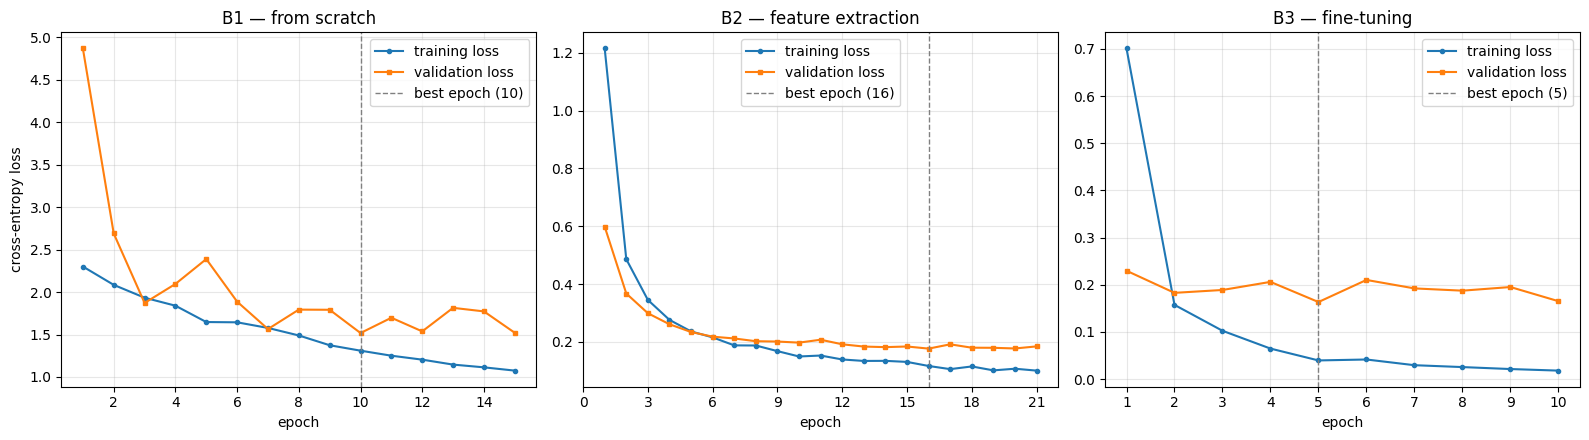

In [18]:
log = pd.DataFrame(EPOCH_LOG)
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))   # sumbu-y terpisah: skala loss B1 jauh lebih besar
for ax, eid, title in zip(axes, ["B1", "B2", "B3"], ["B1 — from scratch", "B2 — feature extraction", "B3 — fine-tuning"]):
    d = log[log.exp_id == eid]
    best = summary.set_index("exp_id").loc[eid, "best_epoch"]
    ax.plot(d.epoch, d.train_loss, "o-", ms=3, label="training loss")
    ax.plot(d.epoch, d.val_loss, "s-", ms=3, label="validation loss")
    ax.axvline(best, ls="--", c="gray", lw=1, label=f"best epoch ({best})")
    ax.set_title(title); ax.set_xlabel("epoch"); ax.grid(alpha=0.3); ax.legend()
    ax.xaxis.set_major_locator(MaxNLocator(integer=True))
axes[0].set_ylabel("cross-entropy loss")
plt.tight_layout(); plt.savefig(RESULTS_DIR / "loss_curves_B1_B2_B3.png", dpi=150); plt.show()

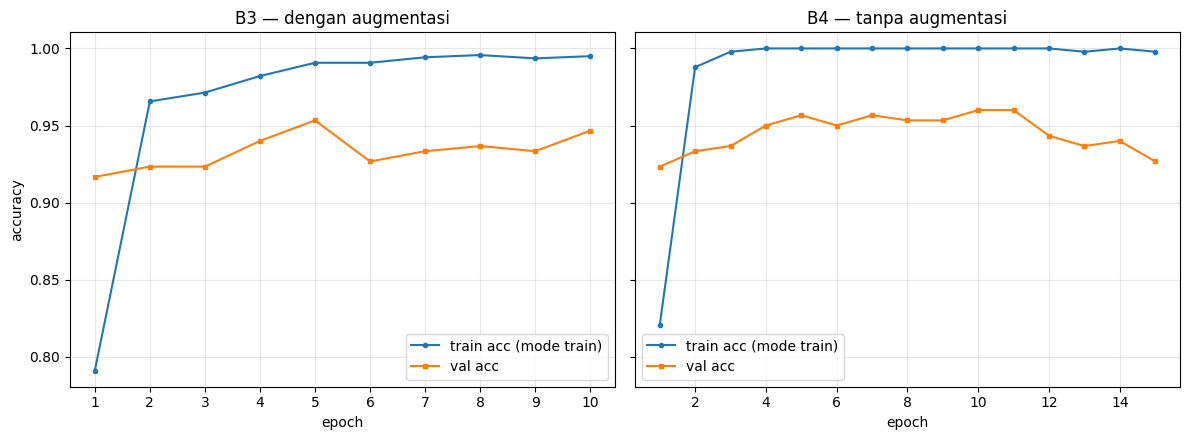

,train_acc_clean,val_acc,gen_gap,best_val_loss,test_macro_f1
exp_id,,,,,
B3,0.992842,0.953333,0.039508,0.163265,0.940241
B4_noaug,1.000000,0.960000,0.040000,0.128918,0.949575


In [19]:
# B4: dengan vs tanpa augmentasi (akurasi train vs val per epoch)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
for ax, eid, title in zip(axes, ["B3", "B4_noaug"], ["B3 — dengan augmentasi", "B4 — tanpa augmentasi"]):
    d = log[log.exp_id == eid]
    ax.plot(d.epoch, d.train_acc, "o-", ms=3, label="train acc (mode train)")
    ax.plot(d.epoch, d.val_acc, "s-", ms=3, label="val acc")
    ax.set_title(title); ax.set_xlabel("epoch"); ax.grid(alpha=0.3); ax.legend()
    ax.xaxis.set_major_locator(MaxNLocator(integer=True))
axes[0].set_ylabel("accuracy")
plt.tight_layout(); plt.savefig(RESULTS_DIR / "augmentation_B3_vs_B4.png", dpi=150); plt.show()

summary.set_index("exp_id").loc[["B3", "B4_noaug"], ["train_acc_clean", "val_acc", "gen_gap", "best_val_loss", "test_macro_f1"]]

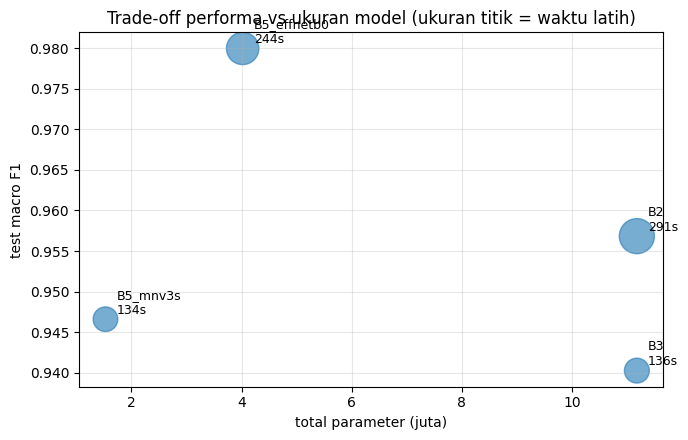

In [20]:
# B5: trade-off Macro F1 vs jumlah parameter vs waktu
cmp = summary[summary.exp_id.isin(["B2", "B3", "B5_effnetb0", "B5_mnv3s"])]
fig, ax = plt.subplots(figsize=(7, 4.5))
sc = ax.scatter(cmp.total_params / 1e6, cmp.test_macro_f1, s=cmp.train_time_s / cmp.train_time_s.max() * 600 + 40, alpha=0.6)
for _, r in cmp.iterrows():
    ax.annotate(f"{r.exp_id}\n{r.train_time_s:.0f}s", (r.total_params / 1e6, r.test_macro_f1), textcoords="offset points", xytext=(8, 4), fontsize=9)
ax.set_xlabel("total parameter (juta)"); ax.set_ylabel("test macro F1"); ax.grid(alpha=0.3)
ax.set_title("Trade-off performa vs ukuran model (ukuran titik = waktu latih)")
plt.tight_layout(); plt.savefig(RESULTS_DIR / "b5_tradeoff.png", dpi=150); plt.show()

## 9. Model terbaik dan failure analysis (C3)

Model terbaik dipilih berdasarkan akurasi validasi (tie-break: validation loss terendah).

Model terbaik: B5_effnetb0 | finetune - EfficientNet-B0 | efficientnet_b0
                   precision    recall  f1-score   support

       Abyssinian      0.966     0.933     0.949        30
           Bengal      0.935     0.967     0.951        30
British Shorthair      0.968     1.000     0.984        30
     Russian Blue      1.000     0.967     0.983        30
          Siamese      1.000     1.000     1.000        30
     Basset Hound      0.967     0.967     0.967        30
           Beagle      0.967     0.967     0.967        30
              Pug      1.000     1.000     1.000        30
          Samoyed      1.000     1.000     1.000        30
        Shiba Inu      1.000     1.000     1.000        30

         accuracy                          0.980       300
        macro avg      0.980     0.980     0.980       300
     weighted avg      0.980     0.980     0.980       300



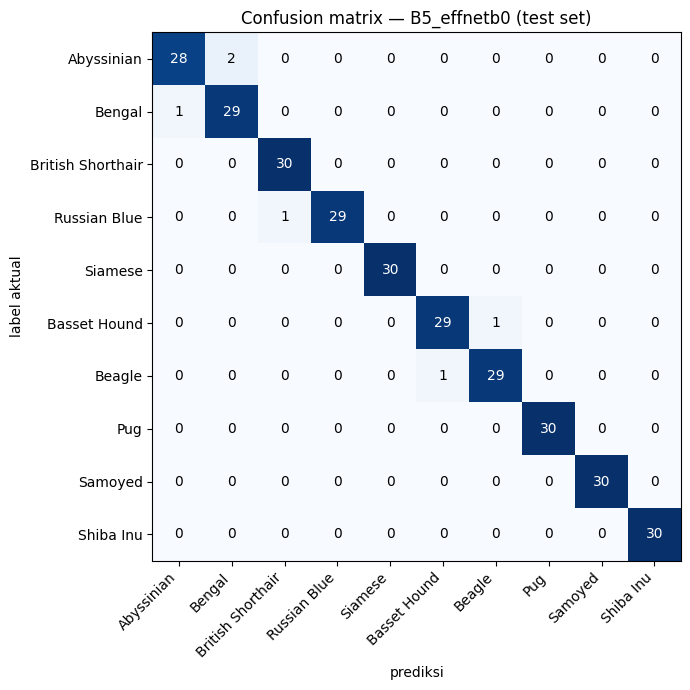

In [21]:
best_row = summary.sort_values(["val_acc", "best_val_loss"], ascending=[False, True]).iloc[0]
BEST_ID = best_row.exp_id
print("Model terbaik:", BEST_ID, "|", best_row.condition, "|", best_row.arch)

pred = pd.read_csv(RESULTS_DIR / f"test_predictions_{BEST_ID}.csv")
print(classification_report(pred.true, pred.pred, labels=SELECTED_CLASSES, digits=3, zero_division=0))

cm = confusion_matrix(pred.true, pred.pred, labels=SELECTED_CLASSES)
fig, ax = plt.subplots(figsize=(8, 7))
ax.imshow(cm, cmap="Blues")
ax.set_xticks(range(NUM_CLASSES)); ax.set_xticklabels(SELECTED_CLASSES, rotation=45, ha="right")
ax.set_yticks(range(NUM_CLASSES)); ax.set_yticklabels(SELECTED_CLASSES)
for i in range(NUM_CLASSES):
    for j in range(NUM_CLASSES):
        ax.text(j, i, cm[i, j], ha="center", va="center", color="white" if cm[i, j] > cm.max() / 2 else "black")
ax.set_xlabel("prediksi"); ax.set_ylabel("label aktual"); ax.set_title(f"Confusion matrix — {BEST_ID} (test set)")
plt.tight_layout(); plt.savefig(RESULTS_DIR / f"confusion_matrix_{BEST_ID}.png", dpi=150); plt.show()

Jumlah salah prediksi di test set: 6 dari 300


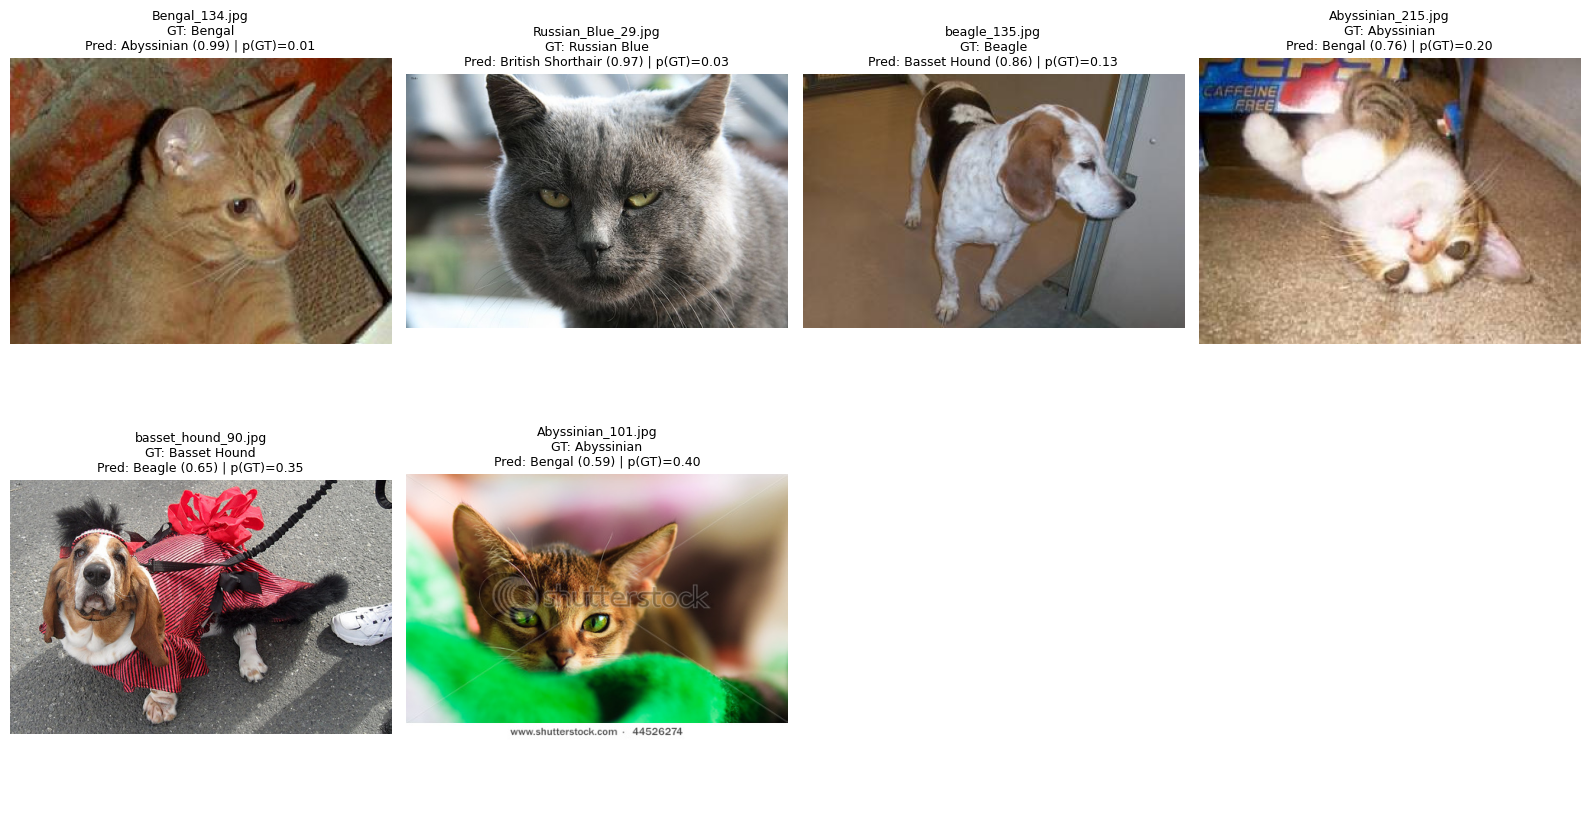

,file,true,pred,confidence,p_true
229,Bengal_134.jpg,Bengal,Abyssinian,0.992526,0.007247
215,Russian_Blue_29.jpg,Russian Blue,British Shorthair,0.968958,0.031013
251,beagle_135.jpg,Beagle,Basset Hound,0.860823,0.133023
18,Abyssinian_215.jpg,Abyssinian,Bengal,0.764036,0.200240
55,basset_hound_90.jpg,Basset Hound,Beagle,0.651068,0.347475
69,Abyssinian_101.jpg,Abyssinian,Bengal,0.590868,0.403197


In [22]:
wrong = pred[pred.true != pred.pred].sort_values("confidence", ascending=False).copy()
prob_cols = [f"p_{c}" for c in SELECTED_CLASSES]
wrong["p_true"] = [r[f"p_{r.true}"] for _, r in wrong.iterrows()]
print(f"Jumlah salah prediksi di test set: {len(wrong)} dari {len(pred)}")

show = wrong.head(8)
show[["file", "true", "pred", "confidence", "p_true"]].to_csv(RESULTS_DIR / f"misclassified_{BEST_ID}.csv", index=False)

path_by_name = {Path(p).name: p for p in test_paths}
n = len(show)
if n > 0:
    cols_ = 4; rows_ = int(np.ceil(n / cols_))
    fig, axes = plt.subplots(rows_, cols_, figsize=(4 * cols_, 4.4 * rows_), squeeze=False)
    for ax, (_, r) in zip(axes.flat, show.iterrows()):
        ax.imshow(Image.open(path_by_name[r.file]).convert("RGB"))
        ax.set_title(f"{r.file}\nGT: {r.true}\nPred: {r.pred} ({r.confidence:.2f}) | p(GT)={r.p_true:.2f}", fontsize=9)
        ax.axis("off")
    for ax in list(axes.flat)[n:]:
        ax.axis("off")
    plt.tight_layout(); plt.savefig(RESULTS_DIR / f"failure_cases_{BEST_ID}.png", dpi=130); plt.show()
show[["file", "true", "pred", "confidence", "p_true"]]

## 10. Eksplorasi tambahan: Grad-CAM pada `layer4` sebelum vs sesudah fine-tuning (C5)

"Sebelum" = model B2: `layer4` masih berisi bobot ImageNet asli (beku), hanya head yang dilatih.
"Sesudah" = model B3: `layer4` sudah disesuaikan ke domain ras hewan. Peta Grad-CAM dihitung untuk
kelas **ground truth**, sehingga kedua model dibandingkan pada pertanyaan yang sama: bagian citra mana
yang menjadi bukti untuk kelas yang benar.

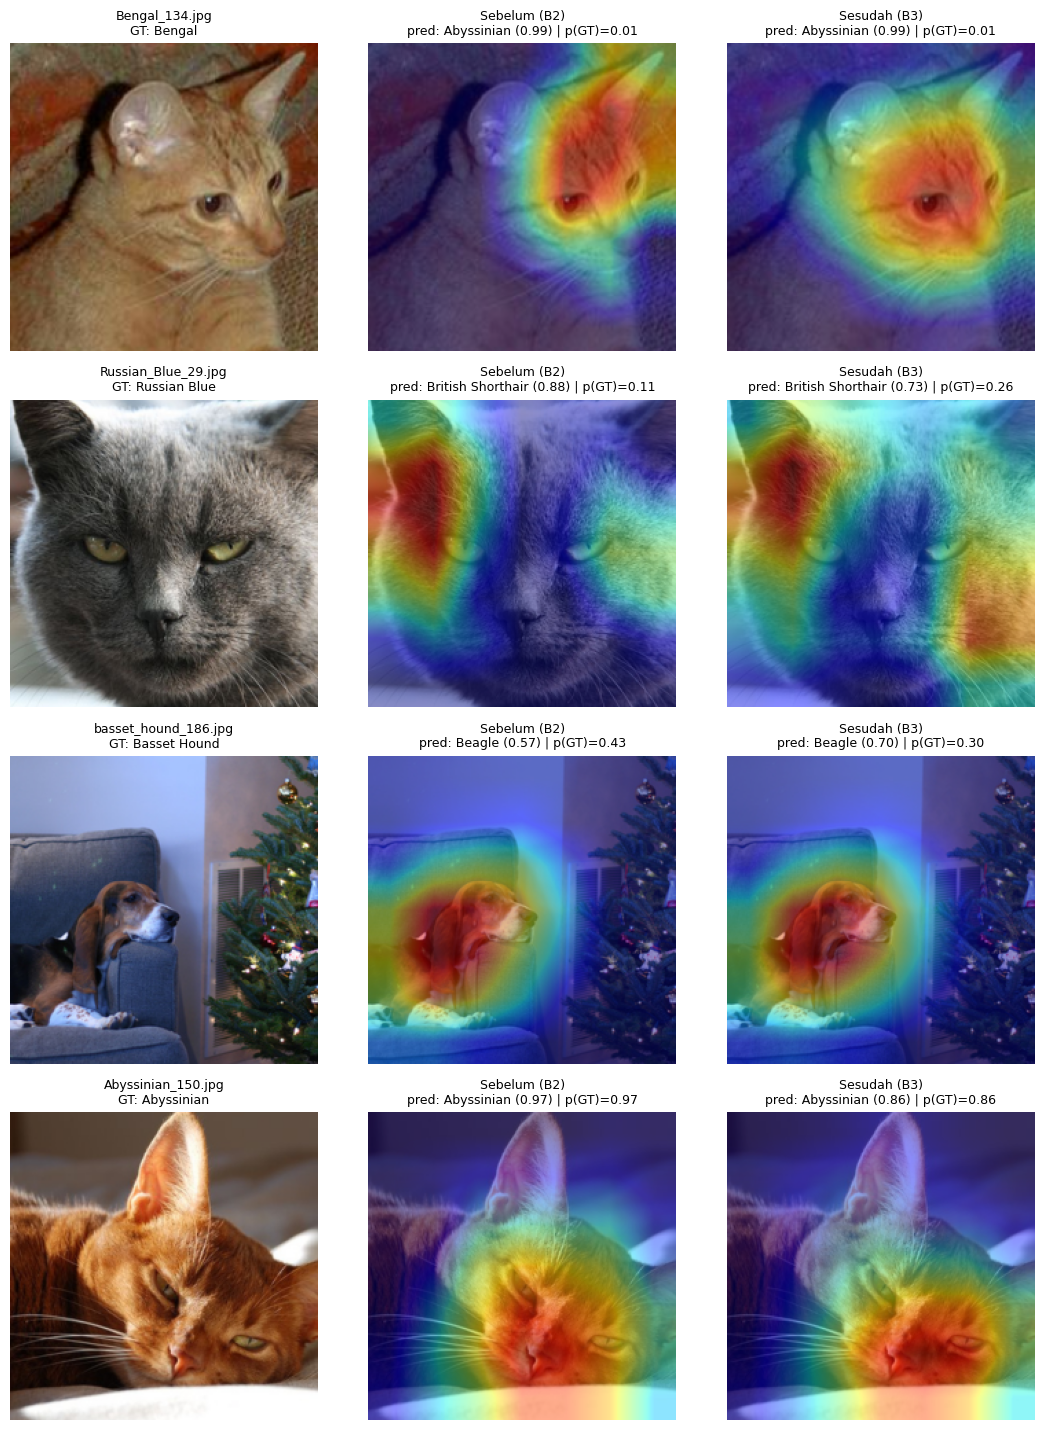

In [23]:
def grad_cam(model, x, target_layer, class_idx):
    store = {}
    def fwd_hook(module, inp, out):
        store["act"] = out
        out.register_hook(lambda g: store.__setitem__("grad", g))
    h = target_layer.register_forward_hook(fwd_hook)
    model.eval()
    x = x.clone().requires_grad_(True)       # agar graf gradien terbentuk walau bobot beku
    logits = model(x)
    model.zero_grad(set_to_none=True)
    logits[0, class_idx].backward()
    h.remove()
    w = store["grad"].mean(dim=(2, 3), keepdim=True)          # bobot per channel = rata-rata gradien
    cam = F.relu((w * store["act"]).sum(dim=1, keepdim=True))
    cam = F.interpolate(cam, size=x.shape[-2:], mode="bilinear", align_corners=False)[0, 0]
    cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)
    return cam.detach().cpu().numpy(), F.softmax(logits, 1)[0].detach().cpu().numpy()

# 2 sampel salah prediksi model terbaik + 2 sampel benar
correct_files = pred[pred.true == pred.pred].sort_values("confidence").file.tolist()
cam_files = wrong.file.tolist()[:2] + correct_files[:2]

fig, axes = plt.subplots(len(cam_files), 3, figsize=(11, 3.6 * len(cam_files)), squeeze=False)
for row, fname in enumerate(cam_files):
    img = Image.open(path_by_name[fname]).convert("RGB")
    x = eval_tf(img).unsqueeze(0).to(device)
    gt = SELECTED_CLASSES.index(pred.set_index("file").loc[fname, "true"])
    axes[row, 0].imshow(denormalize(x[0].cpu())); axes[row, 0].set_title(f"{fname}\nGT: {SELECTED_CLASSES[gt]}", fontsize=9)
    for col, (name, mdl) in enumerate([("Sebelum (B2)", model_b2), ("Sesudah (B3)", model_b3)], start=1):
        cam, p = grad_cam(mdl, x, mdl.layer4, gt)
        axes[row, col].imshow(denormalize(x[0].cpu())); axes[row, col].imshow(cam, cmap="jet", alpha=0.45)
        axes[row, col].set_title(f"{name}\npred: {SELECTED_CLASSES[p.argmax()]} ({p.max():.2f}) | p(GT)={p[gt]:.2f}", fontsize=9)
for ax in axes.flat: ax.axis("off")
plt.tight_layout(); plt.savefig(RESULTS_DIR / "gradcam_B2_vs_B3.png", dpi=130); plt.show()

## 11. Catatan lingkungan dan ekspor hasil

In [24]:
env = {
    "python": __import__("sys").version.split()[0],
    "torch": torch.__version__, "torchvision": torchvision.__version__,
    "numpy": np.__version__, "pandas": pd.__version__,
    "sklearn": __import__("sklearn").__version__,
    "device": torch.cuda.get_device_name(0) if device.type == "cuda" else "cpu",
    "seed": SEED, "batch_size": BATCH_SIZE, "max_epochs": MAX_EPOCHS, "patience": PATIENCE,
    "weight_decay": WEIGHT_DECAY, "classes": SELECTED_CLASSES,
}
with open(RESULTS_DIR / "environment.json", "w") as f:
    json.dump(env, f, indent=2)
print(json.dumps(env, indent=2))
print(sorted(os.listdir(RESULTS_DIR)))

{
  "python": "3.13.15",
  "torch": "2.11.0+cu130",
  "torchvision": "0.26.0+cu130",
  "numpy": "2.1.3",
  "pandas": "2.2.3",
  "sklearn": "1.6.1",
  "device": "Tesla T4",
  "seed": 42,
  "batch_size": 32,
  "max_epochs": 30,
  "patience": 5,
  "weight_decay": 0.01,
  "classes": [
    "Abyssinian",
    "Bengal",
    "British Shorthair",
    "Russian Blue",
    "Siamese",
    "Basset Hound",
    "Beagle",
    "Pug",
    "Samoyed",
    "Shiba Inu"
  ]
}
['augmentation_B3_vs_B4.png', 'augmentation_examples.png', 'b5_tradeoff.png', 'confusion_matrix_B5_effnetb0.png', 'consolidated_table.csv', 'data_split.csv', 'environment.json', 'epoch_log.csv', 'failure_cases_B5_effnetb0.png', 'gradcam_B2_vs_B3.png', 'loss_curves_B1_B2_B3.png', 'misclassified_B5_effnetb0.csv', 'summary.csv', 'summary.json', 'test_predictions_B1.csv', 'test_predictions_B2.csv', 'test_predictions_B3.csv', 'test_predictions_B4_noaug.csv', 'test_predictions_B5_effnetb0.csv', 'test_predictions_B5_mnv3s.csv']


In [25]:
# Unduh folder results/ sebagai ZIP (hanya berjalan di Colab)
import shutil
shutil.make_archive("results", "zip", RESULTS_DIR)
try:
    from google.colab import files
    files.download("results.zip")
except ImportError:
    print("Bukan di Colab: results.zip tersimpan di direktori kerja.")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>